# M1 - Student B: Descriptor design
Project 26: compact learned descriptor vs SIFT / ORB

What I do in this notebook:
1. define the small CNN descriptor
2. compare a few model sizes (params, bytes per descriptor, speed)
3. write the patch extraction around SIFT keypoints and check it works with rotation
4. make some training pairs and run a short training to estimate the training time

## 0. Setup

In [1]:
import os, time
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from skimage import data

# fix seeds so we get the same numbers every run
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# save outputs to our shared drive folder (or a local folder if not on colab)
try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/DIP_P26"
except ImportError:
    OUT = "outputs"
for d in ["tables", "figures", "results"]:
    os.makedirs(f"{OUT}/{d}", exist_ok=True)

device: cuda
Mounted at /content/drive


### Package versions -> requirements.txt
Colab already has everything installed. This just writes down the exact versions we ran with (the course asks for it every milestone).
To rebuild the same environment somewhere else: `pip install -r requirements.txt`

In [2]:
import importlib.metadata as md

pkgs = ["numpy", "pandas", "opencv-python", "matplotlib", "torch", "scikit-image"]
lines = []
for p in pkgs:
    try:
        v = md.version(p).split("+")[0]   # colab torch is like 2.x.x+cu121, pip only knows 2.x.x
        lines.append(f"{p}=={v}")
    except md.PackageNotFoundError:
        print("not installed:", p)

with open(f"{OUT}/requirements.txt", "w") as f:
    f.write("\n".join(lines) + "\n")
print("\n".join(lines))

numpy==2.1.3
pandas==2.2.3
opencv-python==5.0.0.93
matplotlib==3.10.0
torch==2.11.0
scikit-image==0.25.2


# 1. The descriptor model

Same idea as L2-Net / HardNet: only 3x3 convs, two of them with stride 2, and a last 8x8 conv that gives the descriptor.
HardNet uses width 32 and a 128-d output (about 1.3M params). We make it smaller with a `width` and `dim` parameter.

The descriptor model:
Builds our small neural network.
In: a 32×32 grayscale patch. Out: 64 numbers, the fingerprint.
Inside, the network is a stack of filter layers. Each layer looks for patterns: first edges, then corners, then bigger shapes. Two of the layers shrink the image (32 → 16 → 8), and the last one squeezes everything into the 64 numbers.
Before the patch enters, its brightness is evened out, so a dark photo and a bright photo of the same thing look alike to the network.
At the end, the 64 numbers are rescaled to a fixed length, so all fingerprints are comparable.
The quick test feeds in 5 random patches and checks that we get 5 fingerprints of 64 numbers each.

In [3]:

class SmallDesc(nn.Module):
    def __init__(self, width=16, dim=64):
        super().__init__()
        w = width
        self.dim = dim
        self.net = nn.Sequential(
            nn.Conv2d(1, w, 3, padding=1, bias=False), nn.BatchNorm2d(w, affine=False), nn.ReLU(),
            nn.Conv2d(w, w, 3, padding=1, bias=False), nn.BatchNorm2d(w, affine=False), nn.ReLU(),
            # 32x32 -> 16x16
            nn.Conv2d(w, 2*w, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(2*w, affine=False), nn.ReLU(),
            nn.Conv2d(2*w, 2*w, 3, padding=1, bias=False), nn.BatchNorm2d(2*w, affine=False), nn.ReLU(),
            # 16x16 -> 8x8
            nn.Conv2d(2*w, 4*w, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(4*w, affine=False), nn.ReLU(),
            nn.Conv2d(4*w, 4*w, 3, padding=1, bias=False), nn.BatchNorm2d(4*w, affine=False), nn.ReLU(),
            nn.Dropout(0.1),
            # 8x8 -> 1x1, this is the descriptor
            nn.Conv2d(4*w, dim, 8, bias=False), nn.BatchNorm2d(dim, affine=False),
        )

    def forward(self, x):
        # normalize every patch (zero mean, unit std) so brightness changes matter less
        mean = x.mean(dim=(1, 2, 3), keepdim=True)
        std = x.std(dim=(1, 2, 3), keepdim=True) + 1e-7
        x = (x - mean) / std
        x = self.net(x).flatten(1)
        return F.normalize(x, dim=1)   # unit length -> L2 distance between 0 and 2

# quick test
m = SmallDesc()
print(m(torch.rand(5, 1, 32, 32)).shape)   # should be (5, 64)

torch.Size([5, 64])


## 2. Compare model sizes

Compare model sizes:
We try 5 network sizes, from tiny to the size of HardNet (a well-known published model).
For each one we measure:
params: how many numbers the network has to learn (bigger = heavier)
bytes: how much memory one fingerprint takes
cpu / gpu ms: how long it takes to make fingerprints for 1000 patches
SIFT and ORB are added at the bottom for comparison.
The goal is to pick a size that is small and fast but still good.

In [4]:
def count_params(model):
    return sum(p.numel() for p in model.parameters())

def time_model(model, n=1000, dev="cpu"):
    # time to describe n patches (after one warm up run)
    model = model.to(dev).eval()
    x = torch.rand(n, 1, 32, 32, device=dev)
    with torch.no_grad():
        model(x)
        if dev == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        model(x)
        if dev == "cuda": torch.cuda.synchronize()
    return (time.time() - t0) * 1000

torch.set_num_threads(1)   # 1 cpu thread, same rule we use for timing SIFT/ORB

rows = []
for w, d in [(8, 64), (16, 32), (16, 64), (16, 128), (32, 128)]:
    model = SmallDesc(w, d)
    rows.append({
        "model": f"w={w}, d={d}",
        "params (K)": round(count_params(model) / 1000, 1),
        "bytes float": 4 * d,
        "bytes binary": d // 8,
        "cpu ms / 1000 patches": round(time_model(model, dev="cpu"), 1),
        "gpu ms / 1000 patches": round(time_model(model, dev="cuda"), 1) if device == "cuda" else None,
    })
# the classical descriptors for reference
rows.append({"model": "SIFT", "params (K)": 0, "bytes float": 512, "bytes binary": None})
rows.append({"model": "ORB", "params (K)": 0, "bytes float": None, "bytes binary": 32})

torch.set_num_threads(os.cpu_count())
sizes = pd.DataFrame(rows)
sizes

,model,params (K),bytes float,bytes binary,cpu ms / 1000 patches,gpu ms / 1000 patches
0,"w=8, d=64",149.0,256.0,8.0,308.9,12.7
1,"w=16, d=32",202.6,128.0,4.0,778.7,29.7
2,"w=16, d=64",333.7,256.0,8.0,778.7,29.6
3,"w=16, d=128",595.9,512.0,16.0,775.2,29.7
4,"w=32, d=128",1334.6,512.0,16.0,1957.8,73.7
5,SIFT,0.0,512.0,NaN,NaN,NaN
6,ORB,0.0,NaN,32.0,NaN,NaN


w=32, d=128 is the HardNet size. We pick **w=16, d=64** as our main model: about 4x fewer parameters than HardNet and a 256-byte
descriptor (SIFT is 512 bytes). For the stretch goal we can also binarize it to 64 bits = 8 bytes, which is smaller than ORB's 32 bytes.

In [5]:
sizes.to_csv(f"{OUT}/results/m1_model_sizes.csv", index=False)
with open(f"{OUT}/tables/m1_model_sizes.tex", "w") as f:
    f.write(sizes.to_latex(index=False, na_rep="--", float_format="%.1f",
                           caption="Candidate descriptor sizes (32x32 input patch).", label="tab:sizes"))

## 3. Patches around keypoints
For every SIFT keypoint we cut a 32x32 patch that is rotated with the keypoint angle and scaled with the keypoint size,
so the network gets patches that already look roughly the same under rotation/scale.
The window is 6 x keypoint size (about the same area that SIFT itself uses).

Patches around keypoints:
First, SIFT finds interesting spots in the image, called keypoints. Each keypoint has a position, a size and a direction.
This code cuts out a 32×32 square around each keypoint:
turned to match the keypoint’s direction
zoomed to match the keypoint’s size
That’s why a rotated or zoomed photo still gives patches that look the same.

In [6]:
PATCH = 32
MAG = 6.0

def get_patch(img, kp):
    s = MAG * kp.size / PATCH          # image pixels per patch pixel
    a = np.deg2rad(kp.angle)
    c, sn = np.cos(a) * s, np.sin(a) * s
    half = (PATCH - 1) / 2
    x, y = kp.pt
    # affine matrix: patch (u, v) -> image (x, y)
    M = np.array([[c, -sn, x - (c * half - sn * half)],
                  [sn,  c, y - (sn * half + c * half)]], dtype=np.float32)
    return cv2.warpAffine(img, M, (PATCH, PATCH), flags=cv2.WARP_INVERSE_MAP | cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)

def get_patches(img, kps):
    return np.stack([get_patch(img, k) for k in kps]) if len(kps) else np.zeros((0, PATCH, PATCH), np.uint8)

**Check:** rotate an image by 40 degrees, find the same keypoints in both images and compare their patches.
If the rotation handling is right, the two patches should look the same (correlation close to 1).

Rotation check:
A test to make sure the cutting is correct:
Take a photo and a copy rotated by 40°.
Find the same keypoints in both.
Cut patches from both and compare them.
If the patches look alike (correlation close to 1), the cutting works. We got 0.979, so it does.
It also saves a picture showing the patch pairs.

488 matching keypoints
median correlation of patch pairs: 0.979


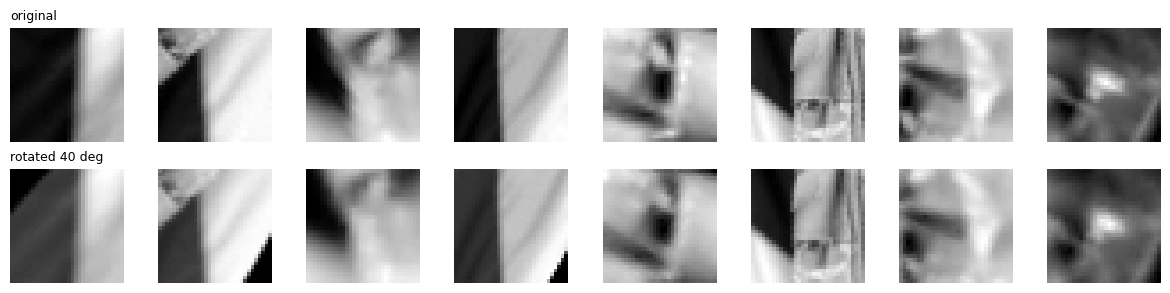

In [7]:
img = cv2.cvtColor(data.astronaut(), cv2.COLOR_RGB2GRAY)
h, w = img.shape
rot = 40
R = cv2.getRotationMatrix2D((w / 2, h / 2), rot, 1.0)
img_rot = cv2.warpAffine(img, R, (w, h))

sift = cv2.SIFT_create(800)
kp1 = sift.detect(img, None)
kp2 = sift.detect(img_rot, None)

# where kp1 should land in the rotated image
pts1 = np.array([k.pt for k in kp1])
pts1_rot = pts1 @ R[:, :2].T + R[:, 2]
pts2 = np.array([k.pt for k in kp2])

pairs = []
for i, p in enumerate(pts1_rot):
    d = np.linalg.norm(pts2 - p, axis=1)
    j = d.argmin()
    # same place and same scale -> same keypoint
    if d[j] < 1 and abs(kp1[i].size - kp2[j].size) < 0.1 * kp1[i].size:
        pairs.append((i, j))
print(len(pairs), "matching keypoints")

p1 = get_patches(img, [kp1[i] for i, _ in pairs]).astype(float)
p2 = get_patches(img_rot, [kp2[j] for _, j in pairs]).astype(float)
corr = [np.corrcoef(a.ravel(), b.ravel())[0, 1] for a, b in zip(p1, p2)]
print("median correlation of patch pairs:", round(np.median(corr), 3))

fig, ax = plt.subplots(2, 8, figsize=(12, 3))
for k in range(8):
    ax[0, k].imshow(p1[k], cmap="gray"); ax[0, k].axis("off")
    ax[1, k].imshow(p2[k], cmap="gray"); ax[1, k].axis("off")
ax[0, 0].set_title("original", loc="left", fontsize=9)
ax[1, 0].set_title(f"rotated {rot} deg", loc="left", fontsize=9)
plt.tight_layout()
plt.savefig(f"{OUT}/figures/m1_patch_check.png", dpi=150)
plt.show()

We get a median correlation above 0.9, so the patches follow the keypoint rotation correctly.

## 4. Training pairs
For the real training (M2) we plan to use the PhotoTour patches (liberty) like HardNet.
Here, to test the pipeline quickly, I make pairs myself: rotate + scale + change brightness of an image, and take the patch
of the same 3D point in both images (anchor / positive). **No HPatches images are used for training.**

Training pairs:
To learn, the network needs examples of “these two patches are the same spot”.
We make them ourselves: take a photo, rotate and zoom it a little, and change its brightness. Then we cut the patch of the same spot from both versions.
Each pair is an anchor (the original patch) and a positive (the same spot in the changed photo).
10 photos are used for training, and 2 are kept aside for testing, so we test on pictures the network has never seen.
No HPatches images are used here, because HPatches is our exam and we must not train on it.

train pairs: 7165  test pairs: 523


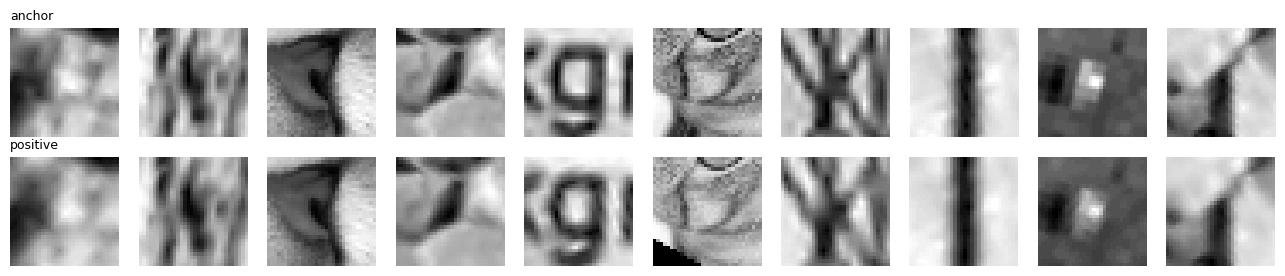

In [8]:
def make_pairs(img, n_max=300):
    h, w = img.shape
    rot = rng.uniform(-30, 30)
    scale = rng.uniform(0.8, 1.2)
    M = cv2.getRotationMatrix2D((w / 2, h / 2), rot, scale)
    img2 = cv2.warpAffine(img, M, (w, h))
    img2 = np.clip(img2 * rng.uniform(0.7, 1.3) + rng.uniform(-20, 20), 0, 255).astype(np.uint8)

    A, P = [], []
    for kp in cv2.SIFT_create(n_max).detect(img, None):
        x2, y2 = M @ [kp.pt[0], kp.pt[1], 1]
        r = 3 * kp.size * scale                      # half window in image 2
        if not (r < x2 < w - r and r < y2 < h - r):  # skip points that leave the image
            continue
        # same point in image 2: moved by M, size * scale, angle - rot
        kp2 = cv2.KeyPoint(x2, y2, kp.size * scale, (kp.angle - rot) % 360)
        A.append(get_patch(img, kp))
        P.append(get_patch(img2, kp2))
    return A, P

# some built-in scikit-image pictures (no download needed)
names = ["astronaut", "camera", "coffee", "chelsea", "rocket", "brick", "grass", "gravel", "coins", "page", "text", "moon"]
imgs = []
for name in names:
    im = getattr(data, name)()
    if im.ndim == 3:
        im = cv2.cvtColor(im[..., :3], cv2.COLOR_RGB2GRAY)
    imgs.append(im.astype(np.uint8))

A, P = [], []
for im in imgs[2:]:          # train images
    for _ in range(3):       # 3 random warps per image
        a, p = make_pairs(im)
        A += a; P += p
A, P = np.array(A), np.array(P)

vA, vP = [], []
for im in imgs[:2]:          # 2 images kept only for testing
    a, p = make_pairs(im)
    vA += a; vP += p
vA, vP = np.array(vA), np.array(vP)
print("train pairs:", len(A), " test pairs:", len(vA))

fig, ax = plt.subplots(2, 10, figsize=(13, 2.8))
for k in range(10):
    i = rng.integers(len(A))
    ax[0, k].imshow(A[i], cmap="gray"); ax[0, k].axis("off")
    ax[1, k].imshow(P[i], cmap="gray"); ax[1, k].axis("off")
ax[0, 0].set_title("anchor", loc="left", fontsize=9)
ax[1, 0].set_title("positive", loc="left", fontsize=9)
plt.tight_layout()
plt.savefig(f"{OUT}/figures/m1_training_pairs.png", dpi=150)
plt.show()

This is only for the M1 test run. Twelve small pictures are enough to check that the code works and to measure training speed, but far too few to train a good descriptor. For the real training at M2, the plan is the PhotoTour dataset (Liberty scene). It has about 450,000 real patches of the same 3D points photographed from different views, and it’s what HardNet was trained on.

## 5. Short training run (to check it learns + estimate time)
Loss: HardNet triplet loss. For every anchor, the hardest negative is the closest *wrong* patch in the batch, and we want
`d(anchor, positive) + 1 < d(anchor, hardest negative)`.

Simple test metric: for every test anchor, is its nearest descriptor among all test positives the correct one? (top-1 accuracy)

Loss and test functions:
The loss tells the network how wrong it is. The rule it learns is: “the fingerprint of the same spot must be closer than the fingerprint of the most similar wrong spot, by a safe margin.”
The test, called top-1 accuracy: for each test patch, find the closest fingerprint among all the others. Is it the correct partner? We report the percentage that are correct.

In [9]:
def triplet_loss(a, p, margin=1.0):
    d = torch.cdist(a, p)                         # all distances in the batch
    pos = d.diag()
    d = d + 10 * torch.eye(len(d), device=d.device)   # hide the positives
    neg = torch.min(d.min(dim=1).values, d.min(dim=0).values)
    return F.relu(margin + pos - neg).mean()

def to_tensor(x):
    return torch.tensor(x, dtype=torch.float32).unsqueeze(1).div(255).to(device)

def top1_acc(model):
    model.eval()
    with torch.no_grad():
        da, dp = model(to_tensor(vA)), model(to_tensor(vP))
    nearest = torch.cdist(da, dp).argmin(dim=1).cpu().numpy()
    return (nearest == np.arange(len(vA))).mean()

Short training run:
Trains the network for 300 small steps. Each step shows it 128 pairs and nudges it to do better.
It prints the loss every 50 steps, and the loss should go down.
It measures top-1 accuracy before and after training.
It also records how long one step takes.
Be honest about one thing: our test pairs are easy, so even the untrained network scores well. This run only proves that the code works and the network learns. It is not a real result.

top-1 before training: 0.979
step 0  loss 0.691
step 50  loss 0.281
step 100  loss 0.174
step 150  loss 0.188
step 200  loss 0.113
step 250  loss 0.174
top-1 after training: 0.989


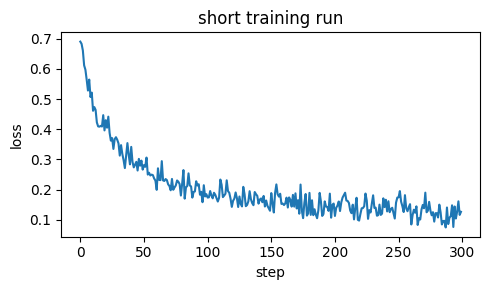

In [10]:
model = SmallDesc(16, 64).to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
print("top-1 before training:", round(top1_acc(model), 3))

STEPS, BATCH = 300, 128
losses = []
model.train()
t0 = time.time()
for step in range(STEPS):
    idx = rng.choice(len(A), BATCH, replace=False)
    loss = triplet_loss(model(to_tensor(A[idx])), model(to_tensor(P[idx])))
    opt.zero_grad()
    loss.backward()
    opt.step()
    losses.append(loss.item())
    if step % 50 == 0:
        print(f"step {step}  loss {loss.item():.3f}")
sec_per_step = (time.time() - t0) / STEPS

print("top-1 after training:", round(top1_acc(model), 3))

plt.figure(figsize=(5, 3))
plt.plot(losses)
plt.xlabel("step"); plt.ylabel("loss"); plt.title("short training run")
plt.tight_layout()
plt.savefig(f"{OUT}/figures/m1_short_training.png", dpi=150)
plt.show()

## 6. Feasibility estimate (for the report)

Feasibility estimate:
Uses the time per step to estimate how long the real training at Milestone 2 will take (20,000 bigger steps).
That number goes in the report, to show the project can run on a free Colab GPU.

In [11]:
# plan for M2: 20 epochs x 1000 steps with batch 512 (4x our batch here)
steps_m2 = 20 * 1000
minutes = sec_per_step * (512 / BATCH) * steps_m2 / 60
print(f"{sec_per_step*1000:.0f} ms per step (batch {BATCH}) on {device}")
print(f"estimated M2 training time: about {minutes:.0f} minutes")

pd.DataFrame([{"device": device, "ms_per_step_batch128": sec_per_step * 1000,
               "estimated_m2_minutes": minutes}]).to_csv(f"{OUT}/results/m1_feasibility.csv", index=False)

23 ms per step (batch 128) on cuda
estimated M2 training time: about 30 minutes


## Summary (goes to the M1 report)
- **Method (sec 4):** SIFT keypoints -> 32x32 rotated/scaled patch -> small CNN (w=16, d=64) -> 64-d descriptor -> matching + RANSAC.
  The detector is the same as SIFT, so any difference against SIFT comes from the descriptor only.
- **Table:** `tables/m1_model_sizes.tex`. **Figures:** `m1_patch_check.png`, `m1_training_pairs.png`, `m1_short_training.png`
- **Feasibility (sec 5):** the time estimate printed above. The project is GPU-light: training fits a free Colab T4.
- **Stretch goal:** binary version of the descriptor and a width x dim speed ablation.